# 05d - Cycle and Age Subset Models

Some NHANES questions were only asked in certain years or age groups. Here we test those extra questions inside their own valid subsets of train.csv to see if they add real value over practical_20. test.csv is not used here.


In [1]:
# imports, train data, and tuned model parameters from experiments/
import json
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.pipeline import Pipeline

from src import evaluate, preprocess
from src.feature_sets import FEATURE_SETS, raw_input_cols

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

df, _ = preprocess.load_train_data()
exp_dir = Path("../experiments")
lr_params = json.loads((exp_dir / "logreg_cv.json").read_text(encoding="utf-8"))["best_params"]
rf_params = json.loads((exp_dir / "rf_cv.json").read_text(encoding="utf-8"))["best_params"]
cb_params = json.loads((exp_dir / "catboost_cv.json").read_text(encoding="utf-8"))["best_params"]

p20 = list(FEATURE_SETS["practical_20"])

oral_clinical_20 = [
    "age", "alcohol_frequency", "weight_to_highest_ratio", "systolic_mean",
    "waist_height_ratio", "bmi", "sex", "education",
    "highest_ever_weight_kg", "weight_kg",
    "self_suspected_gum_disease", "taste_difficulty_1y", "floss_days_7d",
    "self_rated_teeth_and_gums", "loose_tooth_without_injury",
    "persistent_mouth_sensation_1y", "family_diabetes",
    "sleep_problems_or_oversleep_frequency", "self_rated_diet_quality",
    "smoking_status",
]

sleep_symptom_24 = [
    "age", "alcohol_frequency", "weight_to_highest_ratio", "systolic_mean",
    "waist_height_ratio", "bmi", "sex", "education",
    "reported_weight_change_10y_kg", "cigarettes_per_smoking_day",
    "highest_ever_weight_kg", "height_cm", "drinks_per_drinking_day",
    "family_diabetes", "sleep_problems_or_oversleep_frequency",
    "self_rated_diet_quality", "weight_kg",
    "snoring_frequency", "sleep_breathing_difficulty_frequency",
    "daytime_sleepiness_frequency", "serious_vision_difficulty",
    "nightly_urination_count_5plus", "fatigue_frequency_2w",
    "urge_urinary_leakage",
]

age36_extended_24 = p20 + [
    "mouth_aching_frequency_1y",
    "floss_days_7d",
    "self_rated_teeth_and_gums",
    "weight_change_1y_kg",
]

assert len(oral_clinical_20) == 20 and len(set(oral_clinical_20)) == 20
assert len(sleep_symptom_24) == 24 and len(set(sleep_symptom_24)) == 24
assert len(age36_extended_24) == 24 and len(set(age36_extended_24)) == 24
print("train shape:", df.shape)
print("feature counts -> practical_20:", len(p20), "| oral_clinical_20:", len(oral_clinical_20), "| sleep_symptom_24:", len(sleep_symptom_24), "| age36_extended_24:", len(age36_extended_24))


train shape: (12378, 66)
feature counts -> practical_20: 20 | oral_clinical_20: 20 | sleep_symptom_24: 24 | age36_extended_24: 24


In [2]:
# helper to evaluate LogReg, RF, CatBoost, and 50/50 LR+CB blend on a given subset
def eval_subset(sub_df, subset_name, feature_sets_dict):
    sub = sub_df.reset_index(drop=True)
    y_sub = sub["target"].to_numpy()
    sub_splits = evaluate.make_cv_splits(sub)
    rows = []

    for set_label, cols in feature_sets_dict.items():
        raw_cols = raw_input_cols(cols)
        oofs = {}

        # LogReg
        oof_lr = np.zeros(len(sub))
        for tr, va in sub_splits:
            pipe = Pipeline([
                ("prep", preprocess.build_preprocessor("logreg", cols, use_engineered=True)),
                ("clf", LogisticRegression(**lr_params)),
            ])
            pipe.fit(sub.iloc[tr][raw_cols], y_sub[tr])
            oof_lr[va] = pipe.predict_proba(sub.iloc[va][raw_cols])[:, 1]
        oofs["LogReg"] = oof_lr

        # Random Forest
        oof_rf = np.zeros(len(sub))
        for tr, va in sub_splits:
            pipe = Pipeline([
                ("prep", preprocess.build_preprocessor("rf", cols, use_engineered=True)),
                ("clf", RandomForestClassifier(**rf_params, n_jobs=-1)),
            ])
            pipe.fit(sub.iloc[tr][raw_cols], y_sub[tr])
            oof_rf[va] = pipe.predict_proba(sub.iloc[va][raw_cols])[:, 1]
        oofs["Random Forest"] = oof_rf

        # CatBoost
        oof_cb = np.zeros(len(sub))
        for tr, va in sub_splits:
            prep = preprocess.build_preprocessor("catboost", cols, use_engineered=True)
            Xt_tr = prep.fit_transform(sub.iloc[tr][raw_cols])
            Xt_va = prep.transform(sub.iloc[va][raw_cols])
            cat_cols = prep.named_steps["prep"].cat_cols
            clf = CatBoostClassifier(
                **cb_params,
                random_seed=evaluate.SEED,
                verbose=0,
                thread_count=-1,
                allow_writing_files=False,
            )
            clf.fit(Xt_tr, y_sub[tr], cat_features=cat_cols)
            oof_cb[va] = clf.predict_proba(Xt_va)[:, 1]
        oofs["CatBoost"] = oof_cb

        # 50/50 LR + CB blend
        oofs["Blend 50/50 LR+CB"] = 0.5 * oof_lr + 0.5 * oof_cb

        for m_name, p in oofs.items():
            _, m = evaluate.find_best_threshold(y_sub, p)
            brier = round(float(brier_score_loss(y_sub, p)), 4)
            f_aucs = [roc_auc_score(y_sub[va], p[va]) for _, va in sub_splits]
            rows.append({
                "subset": subset_name,
                "n_rows": len(sub),
                "pos_rate": round(float(y_sub.mean()), 4),
                "feature_set": set_label,
                "n_features": len(cols),
                "model": m_name,
                "roc_auc": m["roc_auc"],
                "auc_std": round(float(np.std(f_aucs)), 4),
                "pr_auc": m["pr_auc"],
                "f2": m["f2"],
                "recall": m["recall"],
                "specificity": m["specificity"],
                "precision": m["precision"],
                "brier": brier,
                "threshold": m["threshold"],
            })

    return pd.DataFrame(rows)


## 1. Oral and Dental Health Subset (2011-2014)

We compare our 20-feature oral health set (oral_clinical_20) against practical_20 on 2011-2014 participants, checking both age 40+ and age 20+.


In [3]:
# run 2011-2014 oral_clinical_20 vs practical_20 on age 40+ and age 20+
sub_11_14_40 = df[(df["cycle"].isin(["2011-2012", "2013-2014"])) & (df["age"] >= 40)]
sub_11_14_20 = df[df["cycle"].isin(["2011-2012", "2013-2014"])]

res_oral_40 = eval_subset(
    sub_11_14_40,
    "2011-2014 (age 40+)",
    {"practical_20": p20, "oral_clinical_20": oral_clinical_20},
)
res_oral_20 = eval_subset(
    sub_11_14_20,
    "2011-2014 (age 20+)",
    {"practical_20": p20, "oral_clinical_20": oral_clinical_20},
)
res_oral = pd.concat([res_oral_40, res_oral_20], ignore_index=True)
display(res_oral)


,subset,n_rows,pos_rate,feature_set,n_features,model,roc_auc,auc_std,pr_auc,f2,recall,specificity,precision,brier,threshold
0,2011-2014 (age 40+),3969,0.3963,practical_20,20,LogReg,0.6993,0.0163,0.5884,0.5701,0.5734,0.7008,0.5571,0.2117,0.433
1,2011-2014 (age 40+),3969,0.3963,practical_20,20,Random Forest,0.6923,0.0112,0.5808,0.5539,0.5550,0.7012,0.5494,0.2136,0.438
2,2011-2014 (age 40+),3969,0.3963,practical_20,20,CatBoost,0.6883,0.0139,0.5800,0.5622,0.5645,0.7003,0.5529,0.2148,0.447
3,2011-2014 (age 40+),3969,0.3963,practical_20,20,Blend 50/50 LR+CB,0.6993,0.0155,0.5910,0.5697,0.5722,0.7049,0.5600,0.2114,0.441
4,2011-2014 (age 40+),3969,0.3963,oral_clinical_20,20,LogReg,0.6936,0.0190,0.5832,0.5642,0.5664,0.7024,0.5555,0.2132,0.432
5,2011-2014 (age 40+),3969,0.3963,oral_clinical_20,20,Random Forest,0.6924,0.0117,0.5815,0.5523,0.5531,0.7020,0.5492,0.2136,0.437
6,2011-2014 (age 40+),3969,0.3963,oral_clinical_20,20,CatBoost,0.6898,0.0146,0.5771,0.5605,0.5626,0.7003,0.5521,0.2145,0.448
7,2011-2014 (age 40+),3969,0.3963,oral_clinical_20,20,Blend 50/50 LR+CB,0.6968,0.0174,0.5854,0.5723,0.5760,0.7008,0.5582,0.2122,0.438
8,2011-2014 (age 20+),6580,0.2898,practical_20,20,LogReg,0.7634,0.0106,0.5451,0.6411,0.6959,0.7017,0.4877,0.1699,0.304
9,2011-2014 (age 20+),6580,0.2898,practical_20,20,Random Forest,0.7599,0.0108,0.5388,0.6354,0.6880,0.7036,0.4865,0.1710,0.333


## 2. Sleep, Vision, and Symptom Subset (2015-2018)

We compare practical_20 against an alternative 24-feature sleep and symptom survey (sleep_symptom_24) on 2015-2018 participants.


In [4]:
# run 2015-2018 sleep_symptom_24 vs practical_20
sub_15_18 = df[df["cycle"].isin(["2015-2016", "2017-2018"])]
res_sleep = eval_subset(
    sub_15_18,
    "2015-2018 (age 20+)",
    {
        "practical_20": p20,
        "sleep_symptom_24": sleep_symptom_24,
    },
)
display(res_sleep)


,subset,n_rows,pos_rate,feature_set,n_features,model,roc_auc,auc_std,pr_auc,f2,recall,specificity,precision,brier,threshold
0,2015-2018 (age 20+),5798,0.3032,practical_20,20,LogReg,0.7584,0.0129,0.5407,0.6345,0.6815,0.7005,0.4975,0.1758,0.322
1,2015-2018 (age 20+),5798,0.3032,practical_20,20,Random Forest,0.7523,0.0115,0.5277,0.6135,0.6559,0.7000,0.4875,0.1773,0.357
2,2015-2018 (age 20+),5798,0.3032,practical_20,20,CatBoost,0.7528,0.0102,0.5311,0.6299,0.6758,0.7005,0.4954,0.1774,0.338
3,2015-2018 (age 20+),5798,0.3032,practical_20,20,Blend 50/50 LR+CB,0.7598,0.0114,0.5419,0.6398,0.6877,0.7012,0.5004,0.1752,0.332
4,2015-2018 (age 20+),5798,0.3032,sleep_symptom_24,24,LogReg,0.7580,0.0134,0.5415,0.6405,0.6889,0.7002,0.5000,0.1762,0.319
5,2015-2018 (age 20+),5798,0.3032,sleep_symptom_24,24,Random Forest,0.7503,0.0128,0.5238,0.6160,0.6587,0.7007,0.4892,0.1779,0.358
6,2015-2018 (age 20+),5798,0.3032,sleep_symptom_24,24,CatBoost,0.7520,0.0103,0.5265,0.6305,0.6763,0.7010,0.4960,0.1778,0.344
7,2015-2018 (age 20+),5798,0.3032,sleep_symptom_24,24,Blend 50/50 LR+CB,0.7589,0.0117,0.5401,0.6441,0.6934,0.7000,0.5014,0.1756,0.333


## 3. Age 36+ Screening Cohort (2011-2018)

Diabetes screening usually starts around age 35+, where 10-year weight and dental questions are asked. Here we test adding extra dental and 1-year weight items on age 36+.


In [5]:
# run 2011-2018 age 36+ experiment
sub_age36 = df[df["age"] >= 36]
res_age36 = eval_subset(
    sub_age36,
    "2011-2018 (age 36+)",
    {
        "practical_20": p20,
        "age36_extended_24": age36_extended_24,
    },
)
display(res_age36)


,subset,n_rows,pos_rate,feature_set,n_features,model,roc_auc,auc_std,pr_auc,f2,recall,specificity,precision,brier,threshold
0,2011-2018 (age 36+),8428,0.3813,practical_20,20,LogReg,0.7043,0.0104,0.5699,0.5738,0.5815,0.7008,0.5451,0.2083,0.415
1,2011-2018 (age 36+),8428,0.3813,practical_20,20,Random Forest,0.6987,0.0080,0.5659,0.5589,0.5644,0.7012,0.5380,0.2094,0.427
2,2011-2018 (age 36+),8428,0.3813,practical_20,20,CatBoost,0.7032,0.0096,0.5700,0.5766,0.5846,0.7008,0.5464,0.2082,0.425
3,2011-2018 (age 36+),8428,0.3813,practical_20,20,Blend 50/50 LR+CB,0.7080,0.0099,0.5749,0.5821,0.5909,0.7012,0.5493,0.2069,0.418
4,2011-2018 (age 36+),8428,0.3813,age36_extended_24,24,LogReg,0.7031,0.0111,0.5681,0.5722,0.5797,0.7010,0.5444,0.2086,0.416
5,2011-2018 (age 36+),8428,0.3813,age36_extended_24,24,Random Forest,0.7001,0.0076,0.5675,0.5694,0.5762,0.7018,0.5436,0.2091,0.424
6,2011-2018 (age 36+),8428,0.3813,age36_extended_24,24,CatBoost,0.7038,0.0094,0.5704,0.5749,0.5828,0.7008,0.5456,0.2080,0.425
7,2011-2018 (age 36+),8428,0.3813,age36_extended_24,24,Blend 50/50 LR+CB,0.7079,0.0100,0.5749,0.5837,0.5927,0.7012,0.5501,0.2070,0.417


## 4. Summary Comparison and Save Outputs

Below we compare baseline practical_20 against each subset feature set using the 50/50 LR+CB blend and save the results to experiments/subset_models_summary.json.


,subset,n_rows,pos_rate,candidate_set,base_auc,cand_auc,auc_diff,base_f2,cand_f2,f2_diff,base_recall,cand_recall,base_brier,cand_brier
0,2011-2014 (age 40+),3969,0.3963,oral_clinical_20,0.6993,0.6968,-0.0025,0.5697,0.5723,0.0026,0.5722,0.5760,0.2114,0.2122
1,2011-2014 (age 20+),6580,0.2898,oral_clinical_20,0.7670,0.7653,-0.0017,0.6432,0.6493,0.0061,0.6990,0.7063,0.1688,0.1690
2,2015-2018 (age 20+),5798,0.3032,sleep_symptom_24,0.7598,0.7589,-0.0009,0.6398,0.6441,0.0043,0.6877,0.6934,0.1752,0.1756
3,2011-2018 (age 36+),8428,0.3813,age36_extended_24,0.7080,0.7079,-0.0001,0.5821,0.5837,0.0016,0.5909,0.5927,0.2069,0.2070


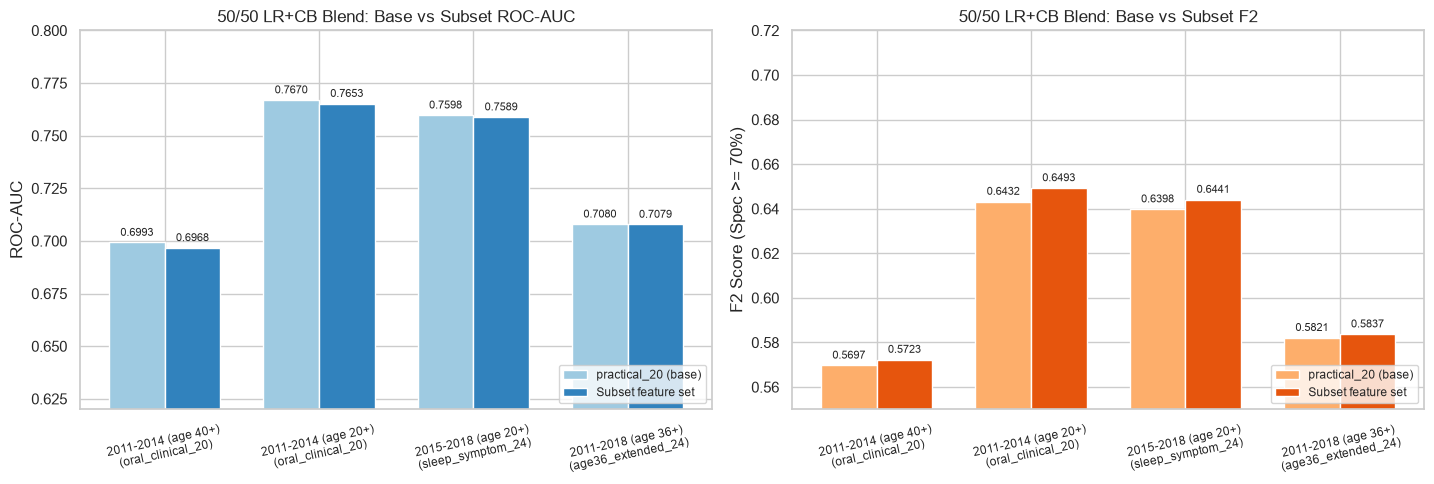

Saved: ../experiments/subset_models_summary.json | total rows: 32


In [6]:
# summarize 50/50 LR+CB blend deltas across all 4 subset tests and save json
all_sub = pd.concat([res_oral_40, res_oral_20, res_sleep, res_age36], ignore_index=True)
blend_sub = all_sub[all_sub["model"] == "Blend 50/50 LR+CB"].copy()

delta_rows = []
for s_name, grp in blend_sub.groupby("subset", sort=False):
    base = grp[grp["feature_set"] == "practical_20"].iloc[0]
    for _, row in grp.iterrows():
        if row["feature_set"] == "practical_20":
            continue
        delta_rows.append({
            "subset": s_name,
            "n_rows": int(row["n_rows"]),
            "pos_rate": row["pos_rate"],
            "candidate_set": row["feature_set"],
            "base_auc": base["roc_auc"],
            "cand_auc": row["roc_auc"],
            "auc_diff": round(float(row["roc_auc"] - base["roc_auc"]), 4),
            "base_f2": base["f2"],
            "cand_f2": row["f2"],
            "f2_diff": round(float(row["f2"] - base["f2"]), 4),
            "base_recall": base["recall"],
            "cand_recall": row["recall"],
            "base_brier": base["brier"],
            "cand_brier": row["brier"],
        })

delta_df = pd.DataFrame(delta_rows)
display(delta_df)

# plot baseline vs candidate ROC-AUC and F2 for the 50/50 LR+CB blend
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
labels = [f"{r['subset']}\n({r['candidate_set']})" for _, r in delta_df.iterrows()]
x = np.arange(len(delta_df))
w = 0.36

b1 = axes[0].bar(x - w / 2, delta_df["base_auc"], width=w, label="practical_20 (base)", color="#9ecae1")
b2 = axes[0].bar(x + w / 2, delta_df["cand_auc"], width=w, label="Subset feature set", color="#3182bd")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=8.5, rotation=12)
axes[0].set_ylim(0.62, 0.80)
axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("50/50 LR+CB Blend: Base vs Subset ROC-AUC")
axes[0].legend(loc="lower right", fontsize=8.5)
for b in list(b1) + list(b2):
    val = b.get_height()
    axes[0].text(b.get_x() + b.get_width() / 2, val + 0.002, f"{val:.4f}", ha="center", va="bottom", fontsize=8)

b3 = axes[1].bar(x - w / 2, delta_df["base_f2"], width=w, label="practical_20 (base)", color="#fdae6b")
b4 = axes[1].bar(x + w / 2, delta_df["cand_f2"], width=w, label="Subset feature set", color="#e6550d")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=8.5, rotation=12)
axes[1].set_ylim(0.55, 0.72)
axes[1].set_ylabel("F2 Score (Spec >= 70%)")
axes[1].set_title("50/50 LR+CB Blend: Base vs Subset F2")
axes[1].legend(loc="lower right", fontsize=8.5)
for b in list(b3) + list(b4):
    val = b.get_height()
    axes[1].text(b.get_x() + b.get_width() / 2, val + 0.002, f"{val:.4f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

summary_payload = {
    "feature_sets": {
        "oral_clinical_20": oral_clinical_20,
        "sleep_symptom_24": sleep_symptom_24,
        "age36_extended_24": age36_extended_24,
    },
    "blend_deltas": delta_df.to_dict(orient="records"),
    "all_results": all_sub.to_dict(orient="records"),
}
out_json = exp_dir / "subset_models_summary.json"
out_json.write_text(json.dumps(summary_payload, indent=2) + "\n", encoding="utf-8")
print("Saved:", out_json, "| total rows:", len(all_sub))


In every subset, the 50/50 LogReg + CatBoost blend beats the single models. Using alternative oral-health (oral_clinical_20) or sleep/symptom (sleep_symptom_24) feature sets, or extending practical_20 for age 36+, gives a slight lift in F2 and recall without improving overall ranking (ROC-AUC) or calibration. This confirms that practical_20 already captures the main signal across all years.
